# 07-控制单元、自动执行与完整计算机系统

> 把手动控制面板换成自动控制单元，让 CPU 能按时钟连续取指、译码和执行，最终把 CPU、内存、输入输出和显存连接成一个可运行的计算机系统。

## 1. 本篇学习范围

本篇对应课程视频 **69—75**：

| 视频 | 标题 | 本篇重点 |
|---|---|---|
| 69 | 把控制引脚接线接出 | 统一模块控制接口 |
| 70 | 控制器的实现原理 | 操作码、步骤与控制信号 |
| 71 | CPU控制单元的绘制 | 将控制器连接到数据通路 |
| 72 | LOAD_A指令的自动执行 | 从内存加载 A |
| 73 | load_B指令的自动执行 | 从内存加载 B |
| 74 | ADD指令的自动执行 | 加法及结果寄存器写入 |
| 75 | 完整的计算机系统 | CPU、内存与输入输出协同 |

已核对配套讲义第 **89—101 页**：程序装载、PC 框架、共同取指阶段、LOAD_A/LOAD_B/ADD/STORE 微操作和控制表。本篇用这些具体表格说明自动执行。

**整理说明：**视频标题与讲义已经核对，视频未逐字转录。接线和编码按讲义记录；用于解释控制器设计、时钟和操作系统关系的通用原理就地标为“补充理解”。第 76—81 个视频留给第 08 篇。


## 2. 从手动开关到自动控制单元

第 06 篇用手动开关完成一次数据传送：先让源寄存器输出，再让目标寄存器在时钟边沿写入。自动 CPU 要把这些动作按顺序重复，因此需要**控制单元（Control Unit）**。

控制单元读取指令中的操作码，结合当前操作步骤，产生各模块的输出使能、写使能和计数使能。其输出改变的是电路的控制状态，数据仍在寄存器、ALU、内存和总线之间流动。

```text
指令操作码 + 当前步骤
          ↓
       控制单元
          ↓
各模块的 OE、WE、EN
          ↓
数据传送 / 运算 / 状态更新
```

例如，“读取内存并装入 A”不对应一个笼统的“执行”按钮，而对应多步：准备地址、内存读入 MBR、MBR 写入 A。控制器把这组动作自动排列起来。


## 3. 控制引脚与寄存器名称

讲义使用 `OE`、`WE`、`EN` 表示主要控制信号。本篇用 `PC.OE` 这类写法表示“PC 的 OE 引脚”，便于追踪信号。

| 名称 | 含义 | 在课程电路中的用途 |
|---|---|---|
| OE（Output Enable） | 输出使能 | 允许寄存器或内存把数据送到对应通路 |
| WE（Write Enable） | 写使能 | 允许目标模块在规定时刻保存输入 |
| EN（Enable） | 使能 | 此处用于允许 PC 计数加一 |
| CLK | 时钟 | 规定同步状态更新时间 |

| 模块 | 中文含义 | 保存的内容 |
|---|---|---|
| PC | 程序计数器 | 下一次取指的位置 |
| MAR | 内存地址寄存器 | 本次内存访问地址 |
| MBR | 内存缓冲寄存器 | 从内存读出或准备写入内存的内容 |
| IR | 指令寄存器 | 当前指令，包括操作码与地址字段 |
| RegA、RegB | 工作寄存器 A、B | ALU 的两个操作数 |
| Output Reg | 结果寄存器 | ALU 的计算结果 |

**补充理解：**`WE` 控制是否写入，`OE` 控制是否输出，两者不同。撤销 OE 不会擦除保存的值；是否高电平有效、是否带反相标记，应按具体元件定义确认。


## 4. 控制器的输入：操作码与当前步骤

讲义第 97—101 页把控制过程写成三列：**操作码、操作步骤、控制信号**。这相当于一张“什么时候打开哪些引脚”的表。

- 操作码决定执行 LOAD_A、LOAD_B、ADD 还是 STORE；
- 操作步骤决定当前正在取指、取数据还是保存结果；
- 控制信号是一组同时需要有效的引脚。

```text
控制输出 = f(操作码, 当前步骤)
```

例如，LOAD_A 和 LOAD_B 的取指动作完全相同；读操作数也相同，最后一步分别打开 `RegA.WE` 或 `RegB.WE`。ADD 则在取指后启用 ALU 和结果寄存器。

**补充理解：**更复杂的处理器还会根据零标志、进位和中断等状态改变控制流程。本课程这组基础指令先关注“操作码 + 步骤”的对应关系。


## 5. 微操作、指令周期与时钟周期

**微操作**是一次较小的硬件动作，例如 `MAR ← PC` 或 `A ← MBR`。一条指令需要多次微操作，才能完成完整的数据移动和运算。

讲义控制表的步骤字段为 3 位，从 `000` 到 `111`，对应 **8 个步骤位置**：

| 步骤 | 作用 |
|---|---|
| 000—011 | 所有基础指令共有的 4 步取指 |
| 100—111 | 根据指令执行实际动作，未使用的步骤为空操作 |

三个层次要区分：

- **时钟周期：**时钟的一次完整节拍；
- **取指/执行阶段：**由多次微操作组成的逻辑阶段；
- **指令周期：**完成一条指令所经历的整个过程。

讲义第 90 页说“包含取指和执行两个周期”，这里是在划分功能阶段；不表示一条指令只有两个时钟周期。按这组 8 步表逐拍推进时，一条指令跨越多个步骤，也不能把它称为“一条指令单周期完成”。


## 6. 把控制表连接成控制单元

搭建时先列控制信号，再画指令译码和步骤选择，最后把每个控制输出接到对应引脚。

```text
IR 的操作码 ──> 指令选择 ─┐
                         ├─> 控制逻辑 ─> 各模块 OE / WE / EN
时钟 ──> 当前步骤 ────────┘
```

推荐顺序：

1. 核对每个寄存器、ALU 和内存的控制端口；
2. 按讲义列出各步骤需要的信号；
3. 实现步骤推进和复位；
4. 先连接所有指令共有的取指信号；
5. 再连接 LOAD_A、LOAD_B、ADD 的执行信号；
6. 逐步观察 MAR、MBR、IR、A、B 和结果寄存器。

**补充理解：**控制表既可由逻辑门/译码器实现，也可把每一步对应的控制位存进控制存储器。后者用“操作码与步骤选中一行，再读出控制字”的思路实现。两种方法都要遵守同一张微操作表；本笔记不把通用实现方式当成视频中未经核对的元件接线。


## 7. 所有指令共有的 4 步取指

讲义第 90、92 页明确列出以下顺序：**先保存 PC 地址，再让 PC 加一，再读取原地址的指令。**

| 步骤 | 微操作 | 有效控制信号 |
|---|---|---|
| 000（第 0 步） | `MAR ← PC` | `PC.OE`、`MAR.WE` |
| 001（第 1 步） | `PC ← PC + 1` | `PC.EN` |
| 010（第 2 步） | `MBR ← 内存[MAR]` | `MAR.OE`、`内存.OE`、`MBR.WE` |
| 011（第 3 步） | `IR ← MBR` | `MBR.OE`、`IR.WE` |

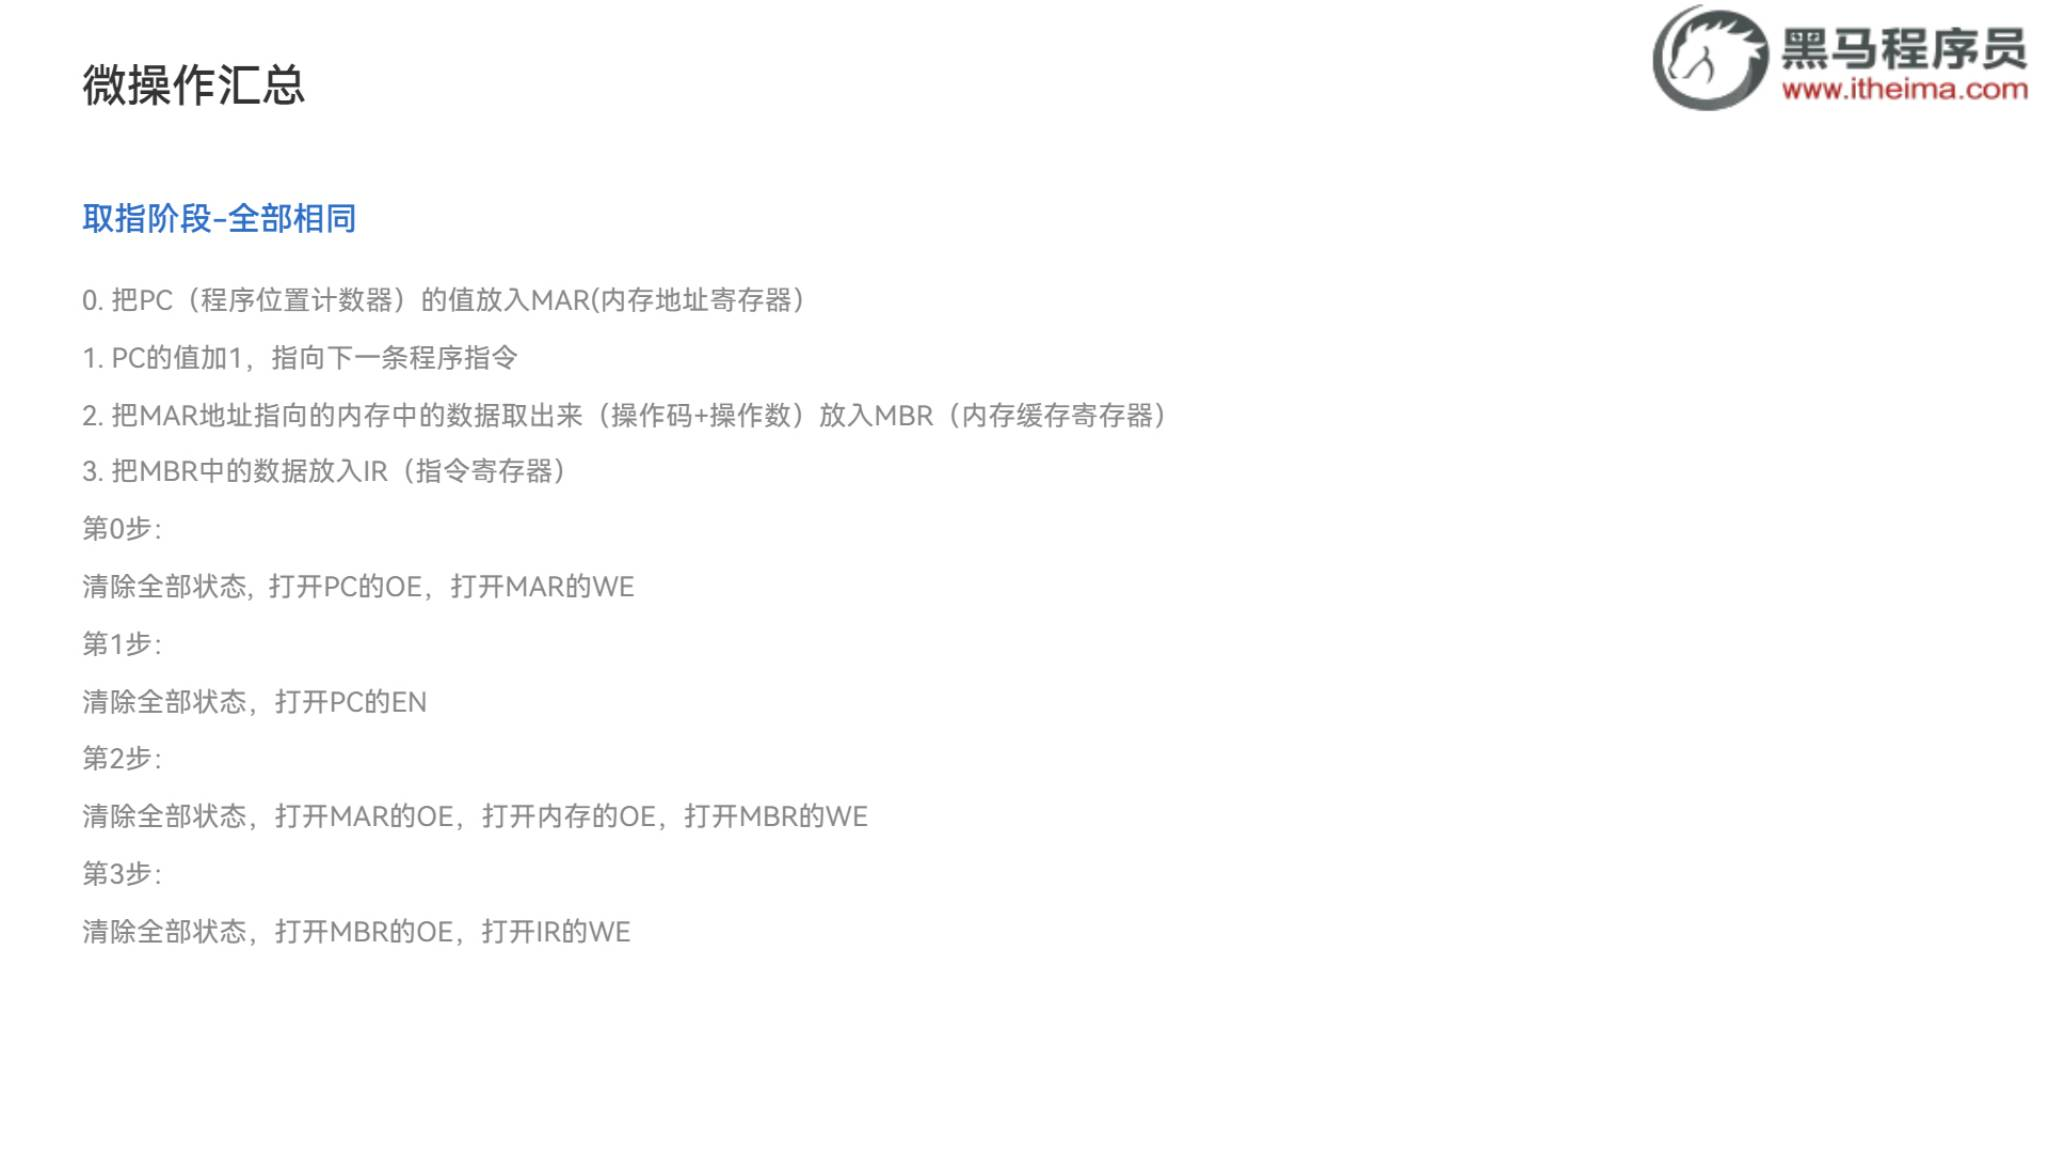

### 为什么 PC 可以先加一？

旧 PC 值已经存进 MAR，所以后续访问内存仍使用原指令地址；PC 此时可以先准备下一条地址。这体现了寄存器“保持中间状态”的作用。

### 讲义中的“清除全部状态”怎么理解？

讲义在每一步前要求清除全部状态，结合上下文，是先撤销上一组手动控制开关，再启用当前步骤需要的 OE/WE/EN。不能理解为每步把 A、B、PC 等寄存器的数据全部清零，否则程序无法连续执行。


## 8. LOAD_A：把内存内容读入 A

课程视频称其为 `LOAD_A`；讲义第 93 页在解释操作码 `0000` 时写作 `MOVE_A`，第 97 页控制表标题仍为 `LOAD_A`。本篇统一用 `LOAD_A`，含义是：

```text
A ← 内存[指令中的地址字段]
```

完成共同取指后，再执行 3 步：

| 执行步骤 | 微操作 | 有效控制信号 |
|---|---|---|
| 100 | `MAR ← IR 的地址字段` | `IR.OE`、`MAR.WE` |
| 101 | `MBR ← 内存[MAR]` | `MAR.OE`、`内存.OE`、`MBR.WE` |
| 110 | `A ← MBR` | `MBR.OE`、`RegA.WE` |
| 111 | 空操作 | 无本指令所需的输出/写入控制 |

IR 输出的是指令中的**地址部分**，不是将整个指令字作为数据写入 A。取指和取操作数虽然都读内存，却是在不同步骤使用不同地址。


## 9. LOAD_A 的完整控制表与控制字

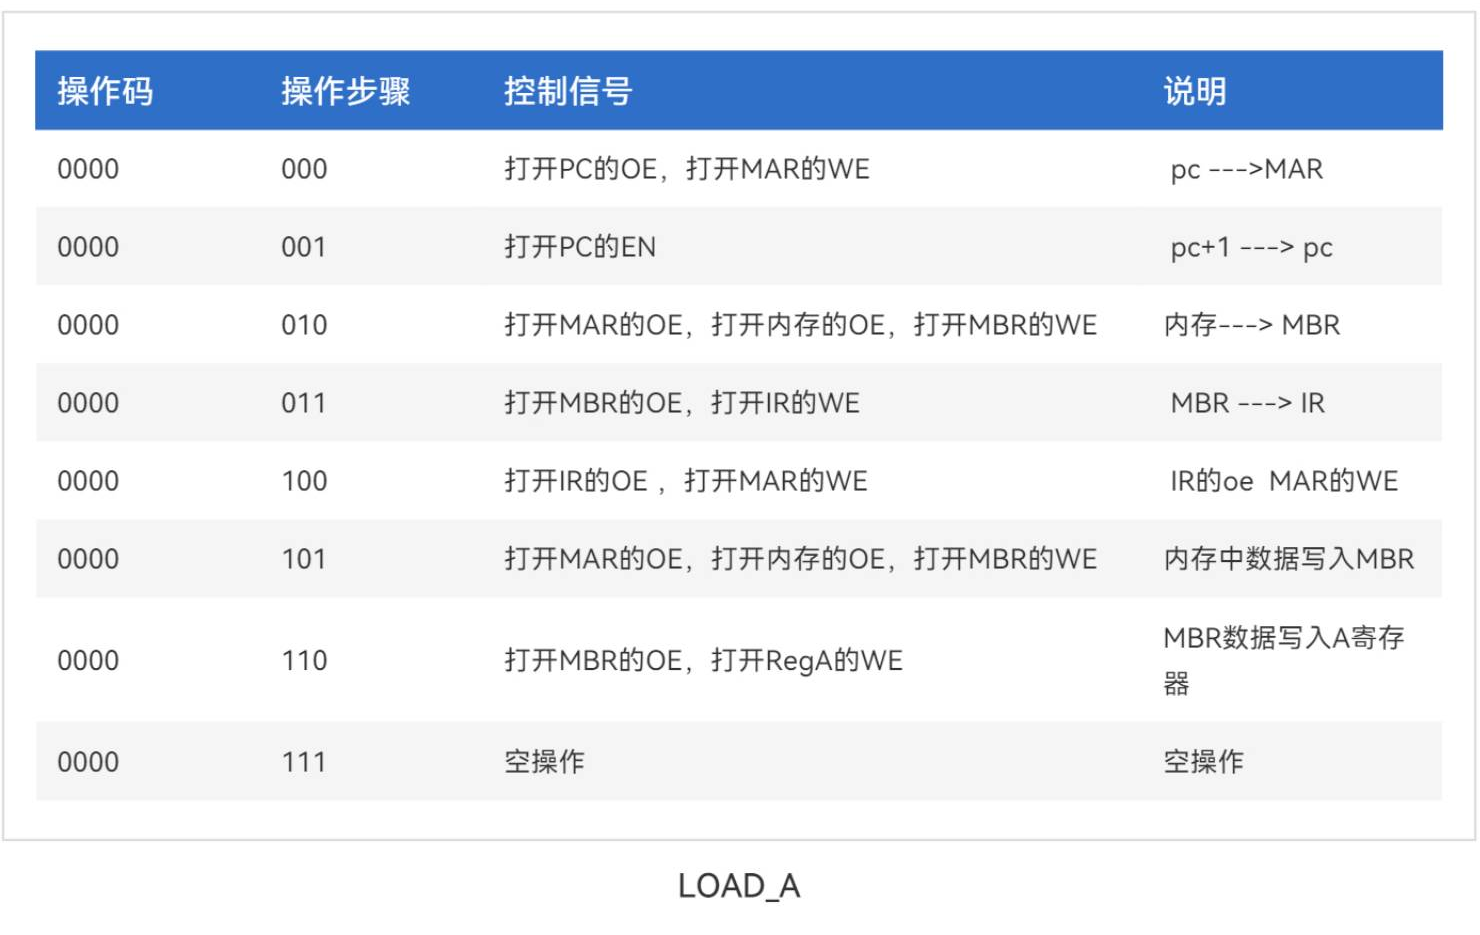

把两段连起来，就是：

```text
000：PC → MAR
001：PC 加一
010：内存[MAR] → MBR        （取指）
011：MBR → IR
100：IR 的地址字段 → MAR
101：内存[MAR] → MBR        （取操作数）
110：MBR → A
111：空操作
```

讲义第 98 页进一步把“打开哪些控制线”写成一串二进制位，即**控制字**。每一位对应一个具体控制引脚，在同一步可以有多位同时有效。

**补充理解：**假设自行定义控制位次序为 `[MBR.OE, IR.WE]`，那么示例控制字 `11` 表示同时让 MBR 输出、让 IR 写入。这个两位例子只演示编码方法；讲义控制字的真实位序须按原理图核对，不能直接套用示例。

机器指令的操作码用于告诉 CPU“做哪件事”；控制字用于告诉电路“这一步打开哪些线”。两者属于不同层次。


## 10. LOAD_B：复用加载路径，改变目标寄存器

`LOAD_B` 的操作码是 `0001`。讲义第 94 页写作 `MOVE_B`，第 99 页表格统一表示其加载行为。

```text
B ← 内存[指令中的地址字段]
```

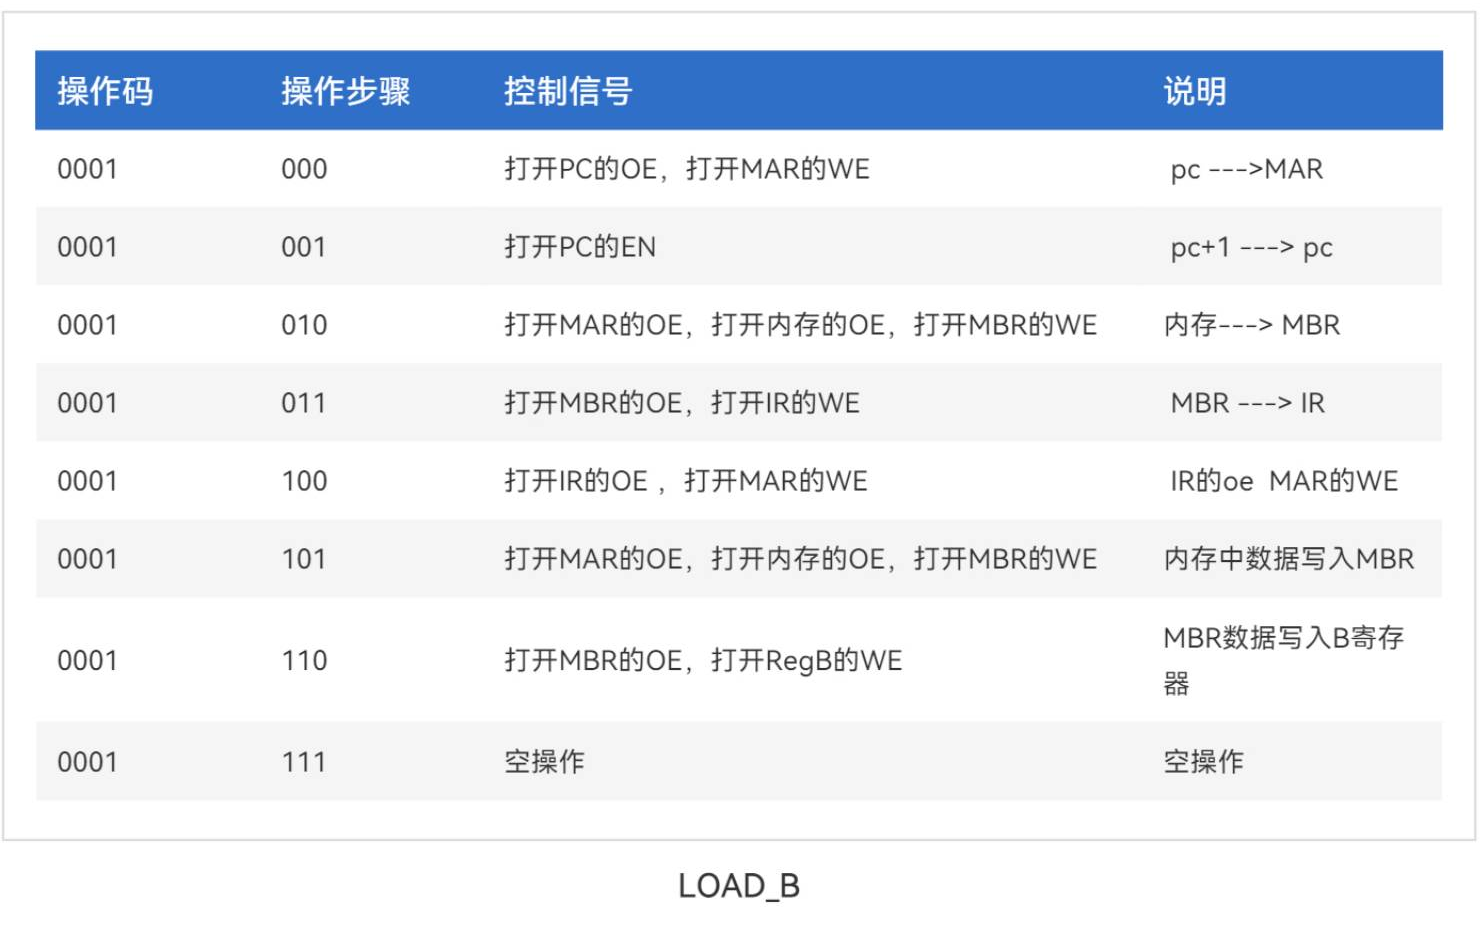

它的 `000—101` 步与 LOAD_A 相同；区别在 `110`：

| 指令 | 第 110 步的控制信号 | 保存结果 |
|---|---|---|
| LOAD_A | `MBR.OE`、`RegA.WE` | MBR → A |
| LOAD_B | `MBR.OE`、`RegB.WE` | MBR → B |

执行 LOAD_B 时，A 应保留原值。若 A 和 B 同时改变，先检查是否误把两根 WE 一起打开。


## 11. ADD：结果写入 Output Reg

ADD 的操作码为 `0010`。讲义第 95、100 页明确使用 **Output Reg 结果寄存器**保存 A+B：

```text
Output Reg ← A + B
```

| 步骤 | 动作 | 有效控制信号 |
|---|---|---|
| 000—011 | 共同取指 | 与 LOAD_A/LOAD_B 相同 |
| 100 | A、B 输入 ALU，计算结果存入 Output Reg | `RegA.OE`、`RegB.OE`、`ALU.OE`、`Output Reg.WE` |
| 101—111 | 空操作 | 无本指令所需的输出/写入控制 |

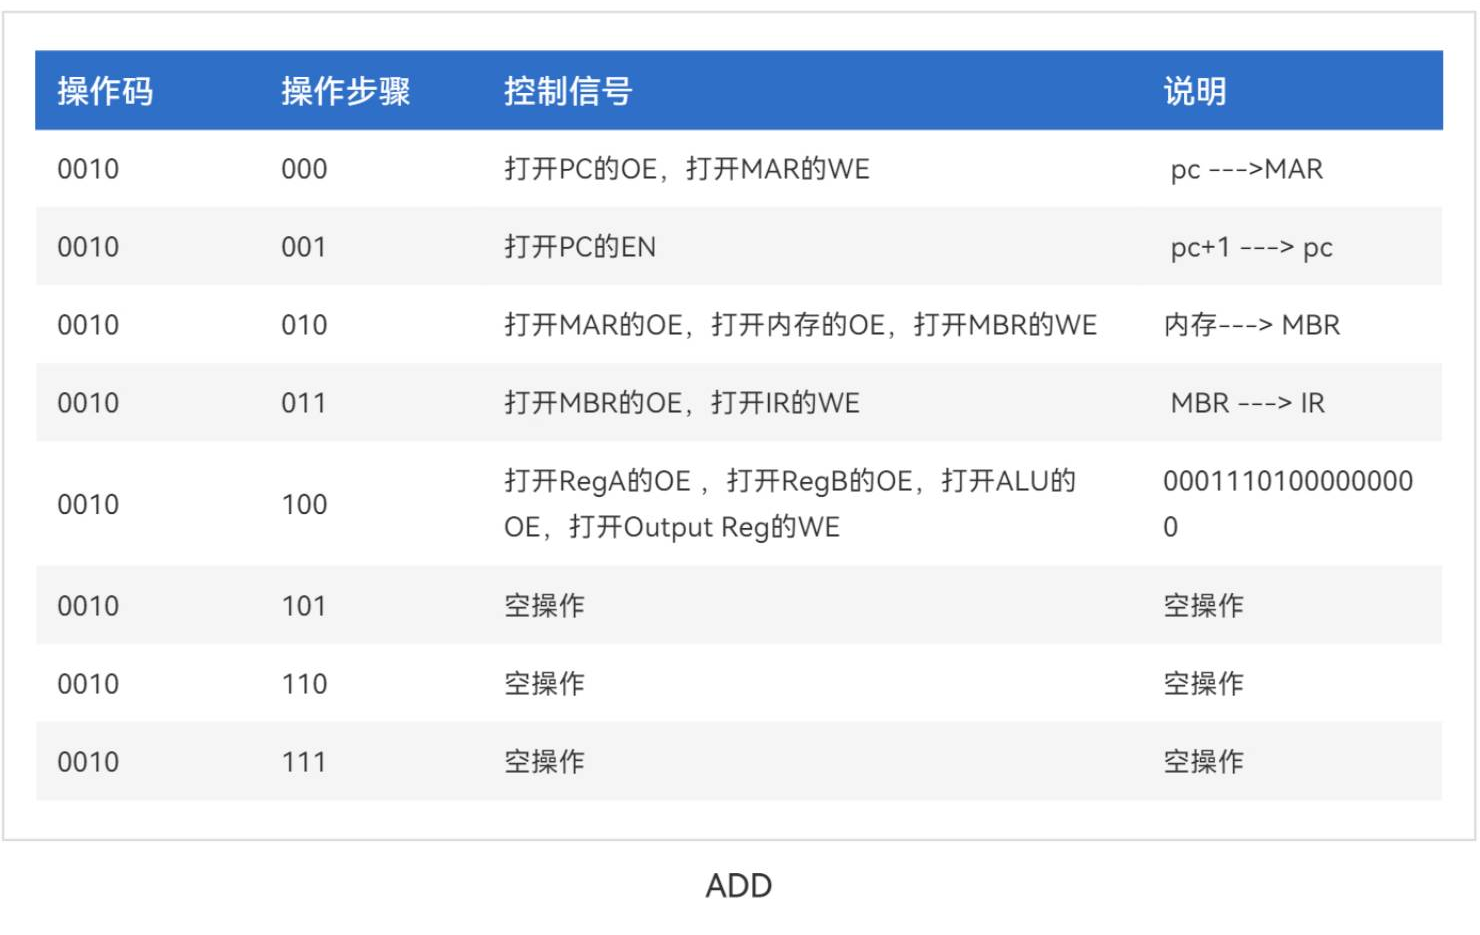

注意两点：

1. A、B 已经保存操作数，ADD 的执行阶段不需要再读一次操作数内存；共同取指阶段仍要读取 ADD 指令。
2. A/B 的 OE 可以同时有效，因为它们在这一步向 ALU 的两路对应输入提供数据。**禁止的是在同一条共享总线上同时驱动不同值**，不是禁止整台 CPU 同时打开两个 OE。

ADD 在执行阶段只做一步有效运算，但整条指令还包含取指和空操作。不能据此判断它是单时钟指令。


## 12. 原讲义程序：从加载到结果存储

讲义第 89 页给出的内存示例包含 4 条程序指令和 2 个数据单元：

| 地址 | 内容 | 解释 |
|---|---|---|
| 0x0 | `0000 1110`（0x0E） | LOAD_A 0xE |
| 0x1 | `0001 1111`（0x1F） | LOAD_B 0xF |
| 0x2 | `0010 0000`（0x20） | ADD |
| 0x3 | `0011 1111`（0x3F） | STORE 0xF |
| 0xE | `0000 0011`（3） | A 的源数据 |
| 0xF | `0000 1011`（11） | B 的源数据，同时也是本例结果存储位置 |

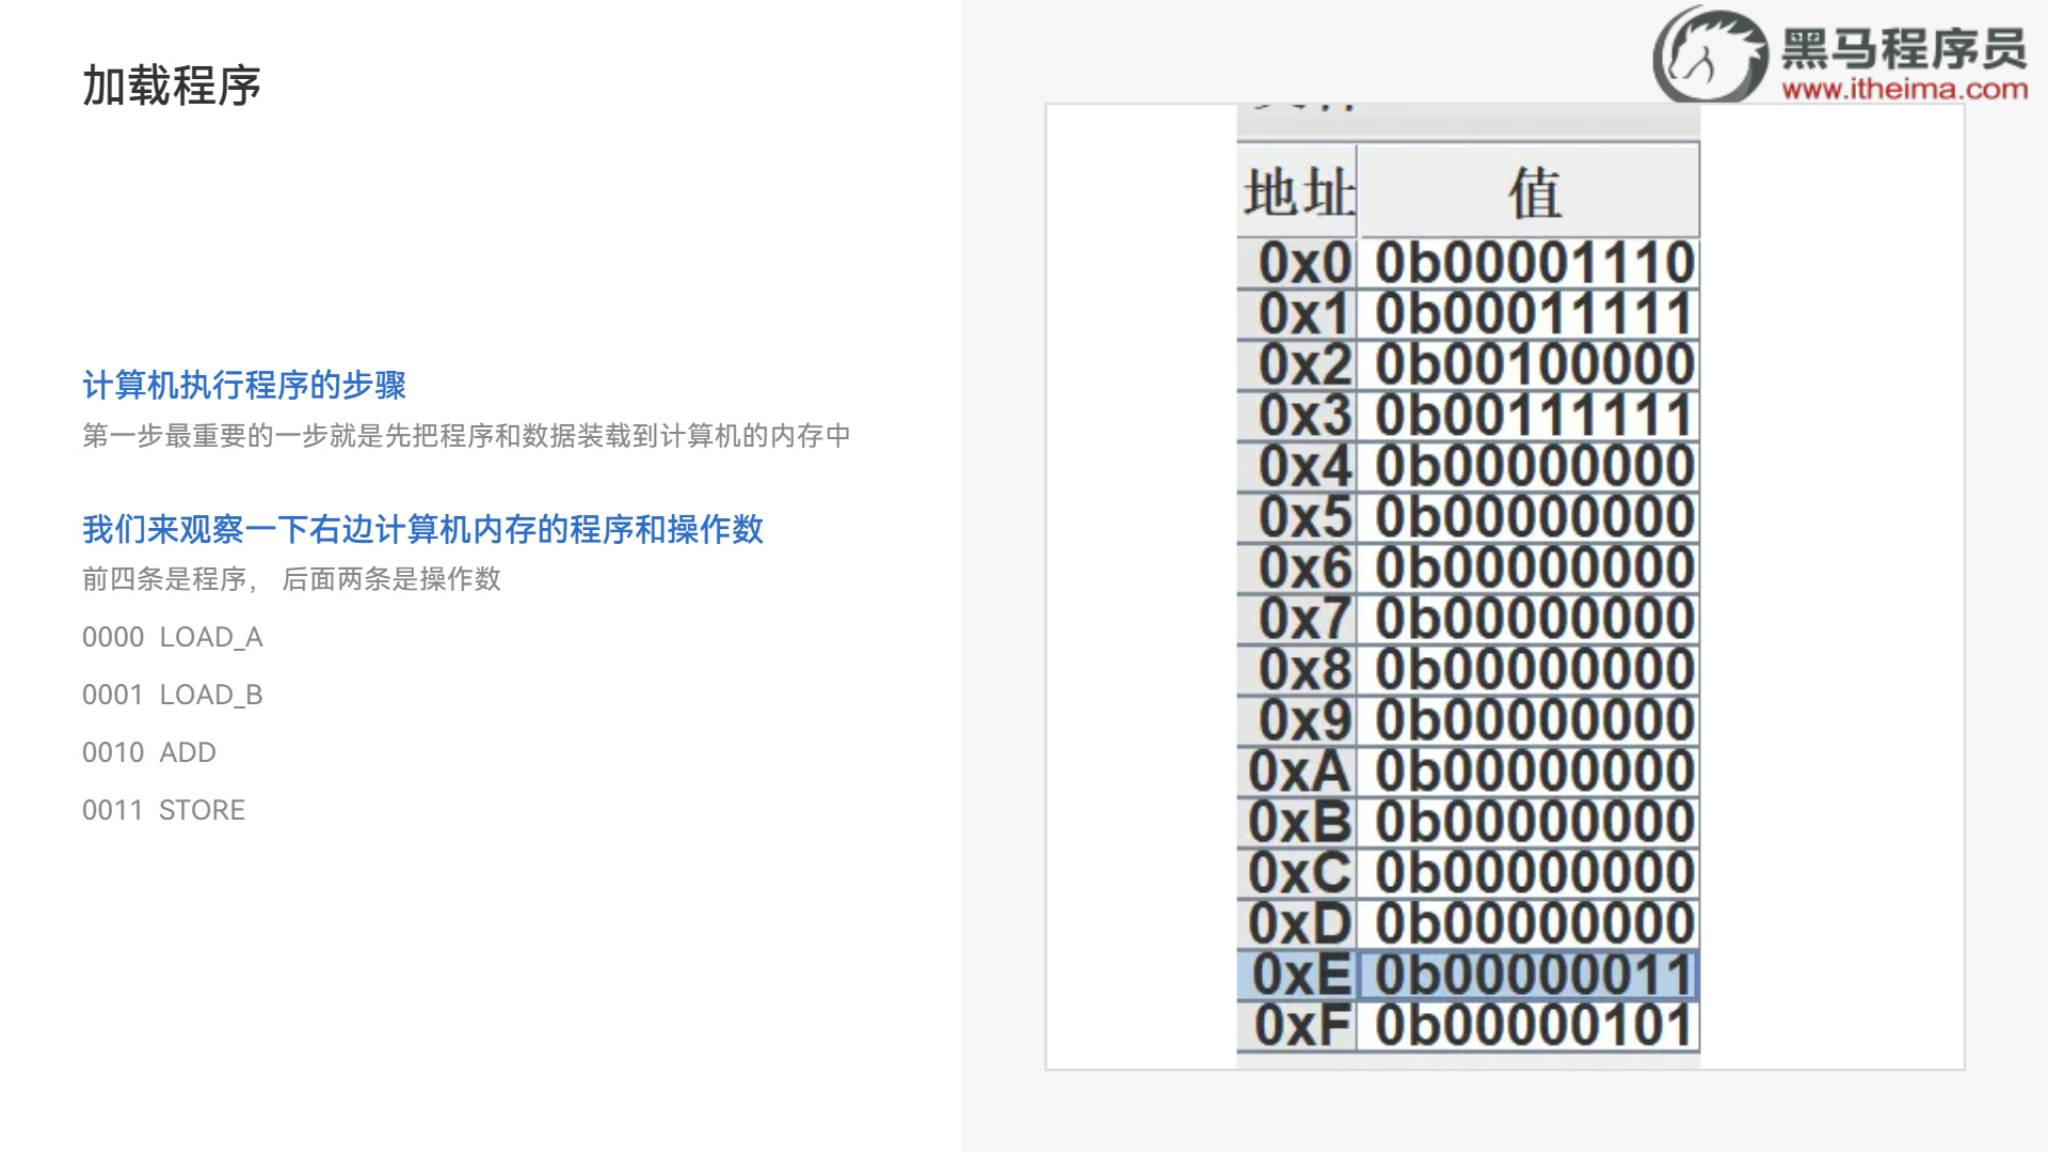

按这个示例的**第一遍执行**，数据变化为：

```text
LOAD_A 0xE：A = 3
LOAD_B 0xF：B = 11
ADD：       Output Reg = 14
STORE 0xF： 内存[0xF] = 14
```

`LOAD_A 0xE` 中的 `0xE` 是内存地址，加载的值是该地址保存的 `3`。它不表示“把 14 直接作为立即数装入 A”。

**补充练习：**若希望重现第 06 篇的 `3+5`，可以把 `内存[0xF]` 的初始数据改为 `00000101`，第一遍运行的结果就是 8；这是修改数据后的练习，不是原图的初始数值。


## 13. PC 位宽、步骤计数与程序结束

讲义第 91 页的框架采用 **2 位 PC**，可以表示 `00、01、10、11` 四个取指位置。它与控制表中的 **3 位步骤字段**承担不同职责：

| 状态 | 含义 | 例子 |
|---|---|---|
| PC | 当前/下一条指令的位置 | 取指地址 0、1、2、3 |
| 步骤计数 | 当前指令进行到哪一步 | 000—111 |

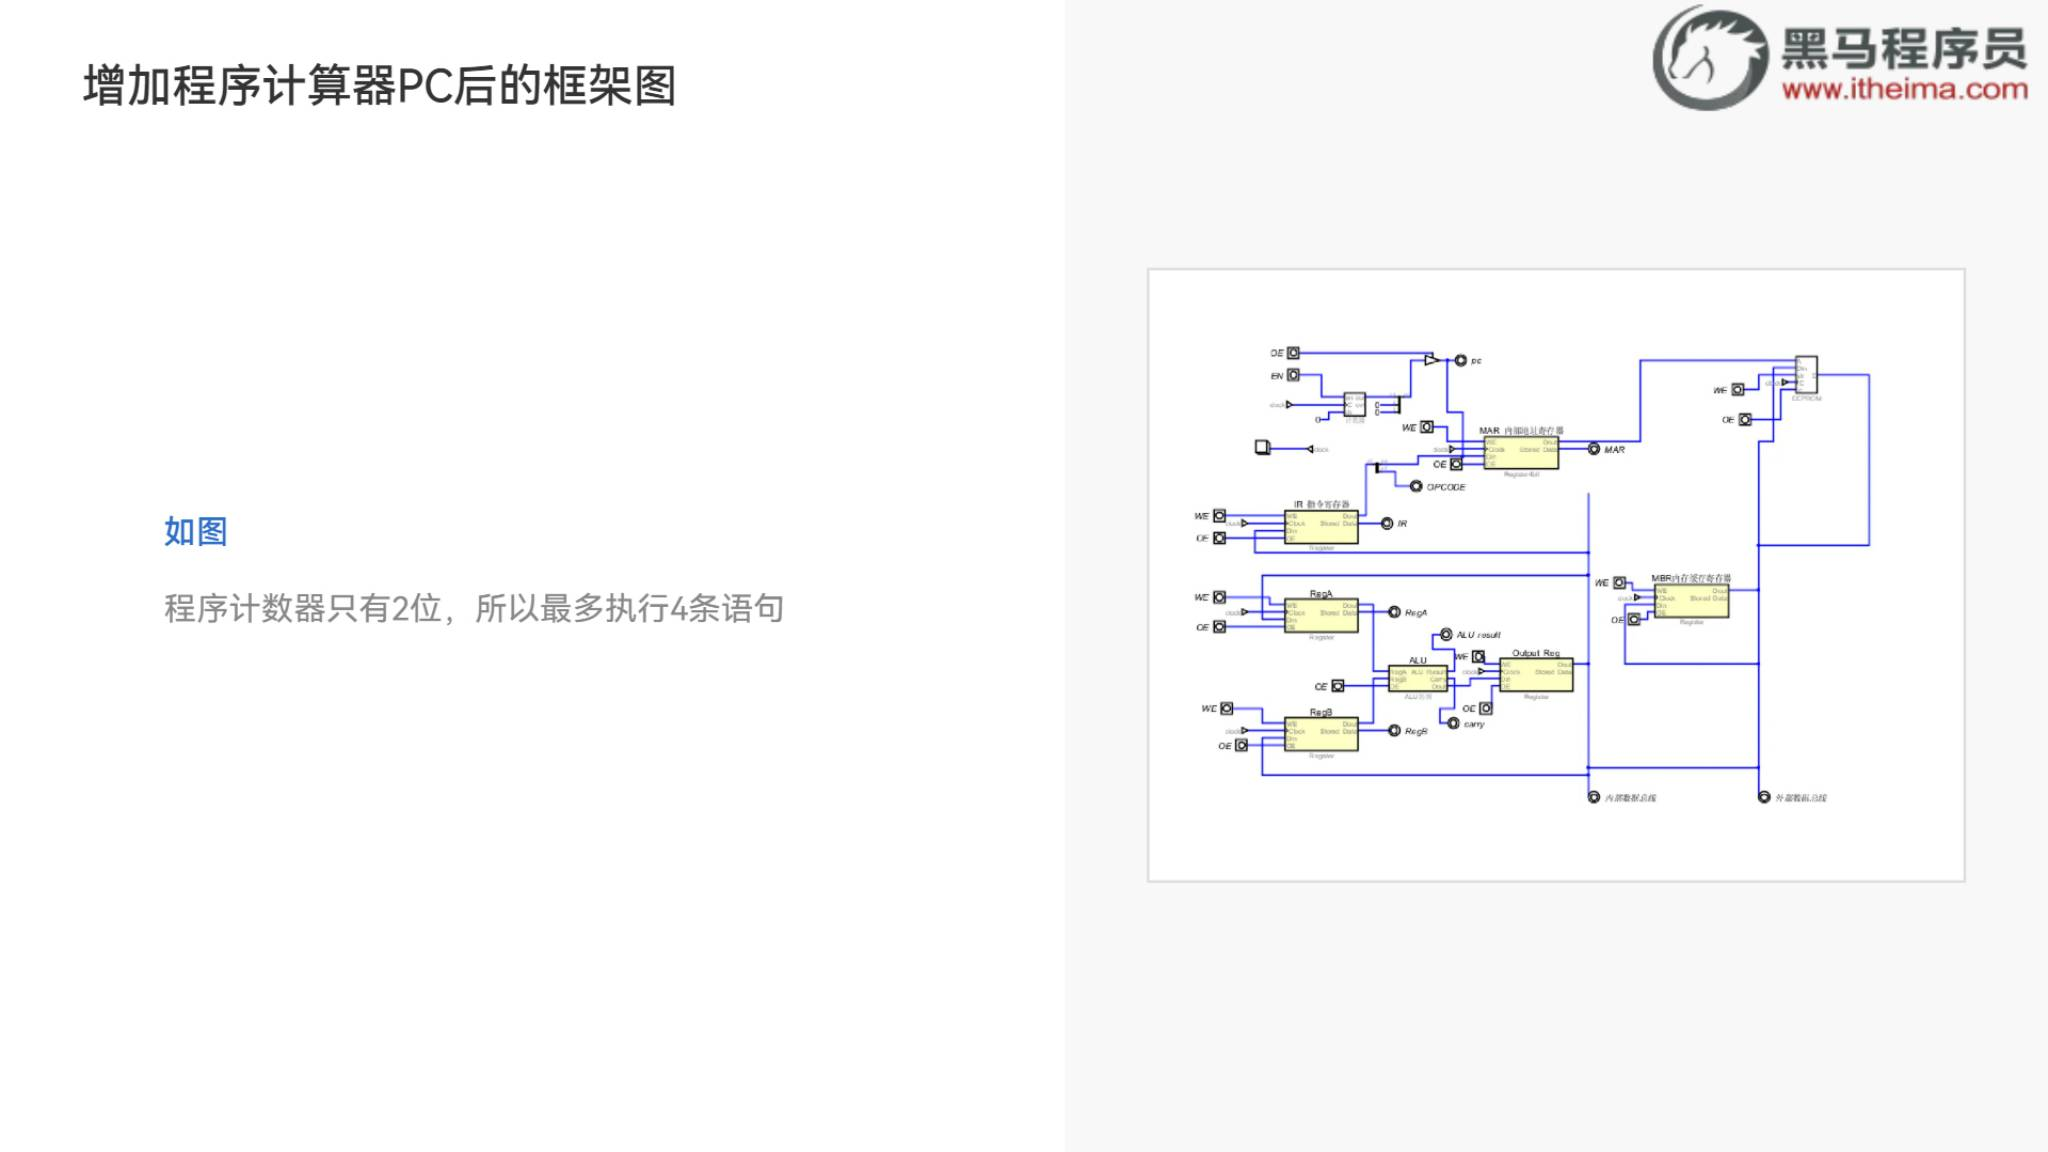

**补充订正：**讲义“最多执行4条语句”适合理解为这个框架只能直接区分四个程序位置。若 2 位 PC 正常计数溢出，它会从 3 回绕到 0；这不自动等于停机。

本篇示例的 STORE 会把结果写回 0xF，覆盖 B 的源数据。如果继续运行并回到 LOAD_B，下一遍读到的是新值，结果就可能继续变化。观察第一遍结果时，应在完成四条指令后暂停；不要假设示例包含未给出的 HALT 指令。


## 14. STORE：把计算结果写回内存

为了理解完整程序，补齐讲义第 96、101 页的 STORE。操作码为 `0011`，行为为：

```text
内存[指令中的地址字段] ← Output Reg
```

取指后有两步有效执行：

| 步骤 | 微操作 | 有效控制信号 |
|---|---|---|
| 100 | `MAR ← 地址字段`，`MBR ← Output Reg` | `IR.OE`、`MAR.WE`、`Output Reg.OE`、`MBR.WE` |
| 101 | `内存[MAR] ← MBR` | `MAR.OE`、`MBR.OE`、`内存.WE` |
| 110—111 | 空操作 | 无本指令所需的输出/写入控制 |

**补充理解：**两项传送在同一步发生，依赖图中对应通路允许并行传输；不能在一条没有隔离的共享总线上同时输出两份数据。照表接线时，还必须追踪数据究竟流经地址路径还是数据路径。

LOAD 侧重“内存 → CPU 寄存器”；STORE 侧重“CPU 结果寄存器 → 内存”。它们复用 MAR 与 MBR，但数据方向相反。


## 15. 自动 CPU 如何成为完整计算机系统

CPU 能自动取指和执行后，还需要与程序/数据内存、输入和输出部件协同工作。这是视频 75 的主题。

```text
                         CPU
            控制单元 + ALU + 寄存器
                          │
               地址 / 数据 / 控制通路
                          │
             ┌────────────┼───────────┐
             ▼            ▼           ▼
           内存         输入设备     输出/显示
```

| 组成 | 作用 |
|---|---|
| CPU | 解释指令并安排计算与数据传送 |
| 内存 | 保存机器指令和数据 |
| 输入 | 把外部状态或用户操作送入系统 |
| 输出 | 将系统结果呈现给用户或外部设备 |
| 总线与控制通路 | 连接各组件并规定访问方向和时序 |

**补充衔接：**第 06 篇的显存是一种显示数据缓冲区。程序可以修改显示数据，显示控制器再按其格式读取。显存和显示控制器如何具体连接，应按课程对应电路确认，不把通用框图当成实物接线图。


## 16. 启动、运行与操作系统的关系

### 16.1 教学程序如何开始运行

先将程序和数据装入内存，设置已知的 PC 与步骤初值，再启动时钟。控制单元持续推进：

```text
取指 → 译码/执行 → 下一条取指 → 译码/执行 → …
```

复位与“撤销上一组控制信号”是两件事：复位使计数器或寄存器进入初始状态；正常步骤切换只应改变当前有效的控制输出，保留程序需要的数据。

### 16.2 补充理解：操作系统处在哪一层

这组硬件已经可以执行预装入的机器程序。更复杂的计算机还会运行操作系统，由它管理任务、内存、文件和设备。

操作系统本身也是由 CPU 执行的软件；CPU 控制单元是硬件，负责每条指令的底层步骤。控制单元完成自动执行，不等于已经实现操作系统。本课程视频 69—75 的核心仍是硬件自动控制与系统连接。


## 17. Digital 仿真的分步观察方法

下面是结合讲义控制表整理的复习练习，先使用单步时钟，确认正确后再连续运行。

| 测试点 | 应看到的状态 |
|---|---|
| 取指 000 后 | MAR 保存旧 PC |
| 取指 001 后 | PC 加一，MAR 仍保存旧地址 |
| 取指 010 后 | MBR 保存指令字 |
| 取指 011 后 | IR 保存指令字 |
| LOAD_A/LOAD_B 执行 101 后 | MBR 保存操作数，内容可能与指令字不同 |
| LOAD_A 执行 110 后 | A 更新，B 不应被这条指令写入 |
| LOAD_B 执行 110 后 | B 更新，A 保持 |
| ADD 执行 100 后 | Output Reg 保存 A+B |
| STORE 执行 101 后 | 目标内存保存 Output Reg 的结果 |

建议记录 `PC、步骤、MAR、MBR、IR、A、B、Output Reg`。当最终输出错误时，沿这组状态找第一个偏离预期的步骤，比只观察最后一盏灯更容易定位原因。


## 18. 常见问题与排错

| 现象 | 优先检查 |
|---|---|
| 读出的指令地址错一位 | 是否在 PC 加一前将旧 PC 写入 MAR |
| IR 正确，但 A/B 读到错误值 | IR 地址字段、MAR 更新、内存数据读取 |
| A 与 B 同时改变 | 目标寄存器的 WE 译码是否混接 |
| MBR 正确，目标寄存器没变化 | 源 OE、目标 WE、时钟边沿 |
| ADD 算对了，但预期寄存器不变 | 课程结果目标是 Output Reg，检查其 WE |
| 总线冲突 | 是否有多个模块驱动同一共享通路 |
| 空操作步骤改变了数据 | 上一步控制输出是否仍然有效 |
| 程序再运行一次结果变了 | STORE 是否覆盖源数据、PC 是否已经回绕 |
| 一启动便从错误阶段执行 | PC、步骤计数及复位初值 |

**补充理解：**单步仿真正确后，再连续运行；在真实同步电路中还要满足传播延迟、建立时间和保持时间。加快时钟不能弥补接线或时序逻辑错误。


## 19. 一页复习表

| 知识点 | 关键结论 |
|---|---|
| 控制单元 | 根据操作码和步骤生成 OE/WE/EN |
| PC 与 MAR | PC 准备下一条，MAR 保留当前访问地址 |
| MBR 与 IR | MBR 缓冲内存数据，IR 保留当前指令 |
| 取指 | MAR←PC；PC+1；MBR←内存[MAR]；IR←MBR |
| LOAD_A（0000） | A←内存[地址字段] |
| LOAD_B（0001） | B←内存[地址字段] |
| ADD（0010） | Output Reg←A+B |
| STORE（0011） | 内存[地址字段]←Output Reg |
| 控制表 | 3 位步骤字段，对应 000—111 |
| 控制字 | 每一位对应一个控制输出，位序由接线定义 |
| 总线约束 | 同一共享通路不同时驱动不同数据 |
| 自动执行 | 控制器接替手动开关，数据通路仍承担实际传送 |
| 完整系统 | CPU 与内存、输入输出及总线协作 |


## 20. 自测题与参考答案

1. 控制单元和 ALU 的职责分别是什么？
2. 为什么 PC 可以在读取本条指令之前先加一？
3. MAR、MBR、IR 分别保存什么？
4. LOAD_A 和 LOAD_B 的哪个执行步骤不同？
5. ADD 的结果在课程电路中保存到哪里？A/B 的 OE 为什么可以同时有效？
6. `LOAD_A 0xE` 是加载数值 14，还是读取地址 0xE 的内容？
7. 原图程序第一遍执行后，Output Reg 与内存[0xF] 分别是多少？
8. 讲义在每步前说“清除全部状态”，为什么不应把所有数据寄存器清零？
9. 2 位 PC 经过地址 3 后是否一定自动停机？
10. 控制字与机器指令的操作码有什么区别？

### 参考答案

1. 控制单元安排数据传送与状态更新；ALU 对输入数据做运算。
2. 旧 PC 已经写入 MAR，内存仍用 MAR 保留的原地址读取。
3. MAR 保存本次内存地址；MBR 保存读出或待写的数据；IR 保存当前指令。
4. 110 步分别启用 RegA.WE 或 RegB.WE，其余加载流程相同。
5. 保存到 Output Reg；A/B 分别向 ALU 的两路输入提供数据，不能把这个动作误认为共享总线争用。
6. 读取内存地址 0xE 的内容；原图中该位置保存 3。
7. A=3、B=11，所以两者都是 14；STORE 把 Output Reg 写入 0xF。
8. 此处应撤销上一组控制开关，数据仍须保留，否则指令执行过程中状态会丢失。
9. 不一定。正常 2 位计数会回绕到 0；停止需要暂停时钟或另设停止控制。
10. 操作码选择指令类型；控制字指定某一步实际有效的控制引脚。


## 21. 与课程资料的对应关系

| 本篇内容 | 视频对应 | 已核对讲义 |
|---|---|---|
| 控制引脚、译码与步骤控制 | 69—71 | 90—92、97—101 页的流程与控制表 |
| LOAD_A 自动执行 | 72 | 93、97、98 页 |
| LOAD_B 自动执行 | 73 | 94、99 页 |
| ADD 自动执行 | 74 | 95、100 页 |
| 程序与结果存储的完整衔接 | 75 的系统主题 | 89、91、96、101 页的程序、PC与STORE |

讲义第 93—94 页使用 MOVE_A/MOVE_B，第 89、97、99 页和视频使用 LOAD_A/LOAD_B。本篇说明了这一命名差异，并按讲义的“内存地址加载”语义整理。

来源：[《自己动手做台计算机》课程资料](https://pan.baidu.com/s/1RLiC8gC1sXTu7EgkQs9oHw?pwd=6633)，提取码 `6633`。配套讲义为 `ppt/自己动手做台计算机.pdf`，共 101 页。本篇原图以内嵌附件保存，打开 Notebook 不需要依赖网盘预览链接。

**核对范围：**课程视频目录及讲义第 89—101 页；未逐字转录视频。自测、排错和标明的“补充理解”是为复习编写的说明。
